# 02 · Modelling

**Goal:** predict if a player gets into the Hall of Fame.

**Plan:**
1. Load table one row per player.
2. Split it: old players to train on, newer players to test on.
3. Try 2 simple rules (baselines) and 4 models.
4. Train each model 3 ways:
    - stats only
    - honours only
    - both stats and honours
5. Compare the results on the test players.

## 1. Load the data

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.utils.class_weight import compute_sample_weight
from data_prep import load_table, ROOT, PERFORMANCE_FEATURES, HONOURS_FEATURES

df = load_table()
print(df.shape)
df.head()

Step 1  extract: C:\Users\Smugg\Documents\Uniguelph\CIS 4020\Cis4020FinalProject\cis4020-hof\data\raw\lahman_2025
Step 2  clean:   span 20,423, batting 20,423, pitching 10,599, honours 2,456, position 24,011, hof 281, people 24,270
Step 3  join:    2,110 eligible players x 43 columns -> C:\Users\Smugg\Documents\Uniguelph\CIS 4020\Cis4020FinalProject\cis4020-hof\data\processed\hof_players.csv
        test :   695 players,  33 inducted (4.7%)
        train:  1415 players,  98 inducted (6.9%)
(2110, 43)


,playerID,name,first_year,final_year,pos,split,seasons,G,PA,R,...,pos_dh,AllStar,MVP,CyYoung,GoldGlove,ROY,WS_MVP,HOF,hof_year,hof_route
0,aaronha01,Hank Aaron,1954,1976,of,train,23,3298,13919,2174,...,0,21,1,0,3,0,0,1,1982,BBWAA
1,aasedo01,Don Aase,1977,1990,p,train,13,448,5,0,...,0,1,0,0,0,0,0,0,<NA>,NaN
2,abbotgl01,Glenn Abbott,1973,1984,p,train,11,248,0,0,...,0,0,0,0,0,0,0,0,<NA>,NaN
3,abbotji01,Jim Abbott,1989,1999,p,test,10,263,21,0,...,0,0,0,0,0,0,0,0,<NA>,NaN
4,abbotpa01,Paul Abbott,1990,2004,p,test,11,162,20,2,...,0,0,0,0,0,0,0,0,<NA>,NaN


## 2. Split into train and test
- **Train:** players whose career ended 1995 or earlier. The models learn from these.


- **Test:** players whose career ended 1996-2010. The models have never seen these so they show how good the model really is.

HOF is the answer: 1 = in the Hall of Fame and 0 = not.

In [2]:
train = df[df['split'] == 'train']
test = df[df['split'] == 'test']

y_train = train['HOF']
y_test = test['HOF']

print('Train players:', len(train), ' Hall of Famers:', y_train.sum())
print('Test players: ', len(test), ' Hall of Famers:', y_test.sum())

Train players: 1415  Hall of Famers: 98
Test players:  695  Hall of Famers: 33


## 3. Three sets of inputs
- **performance:** career stats and position
- **honours:** All-Star picks and awards
- **combined:** both

This lets us ask: how much do honours add on top of stats?

In [3]:
feature_sets = {
    'performance': PERFORMANCE_FEATURES,
    'honours': HONOURS_FEATURES,
    'combined': PERFORMANCE_FEATURES + HONOURS_FEATURES,
}

## 4. How we score the models
Only about 5% of players are in the Hall of Fame so "predict nobody" would be 95% accurate but useless.


So the main score is PR AUC.

It checks if the real Hall of Famers are ranked near the top and Higher is better (max 1.0).

We also report:
- **precision:** of the players we said "yes" to how many really got in
- **recall:** of the real Hall of Famers how many we found
- **F1:** one number that mixes precision and recall

To turn a probability into yes/no we need a threshold. We pick the one with the best F1 on the training players only.

In [4]:
def best_threshold(y, scores):

    # try every possible threshold keep the one with the best F1
    precision, recall, thresholds = precision_recall_curve(y, scores)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thresholds[np.argmax(f1[:-1])]

def get_results(name, features, scores, threshold):

    # score one model on the test players
    guess = (scores >= threshold).astype(int)
    right = ((guess == 1) & (y_test == 1)).sum()
    precision = right / max(guess.sum(), 1)
    recall = right / y_test.sum()

    return {
        'model': name,
        'features': features,
        'PR_AUC': average_precision_score(y_test, scores),
        'ROC_AUC': roc_auc_score(y_test, scores),
        'F1': 2 * precision * recall / max(precision + recall, 1e-12),
        'precision': precision,
        'recall': recall,
    }

all_results = []       # one row per model
test_scores = {}       # each model's test probabilities

## 5. Baselines (simple rules no learning)
Any real model has to beat these.
1. **Milestones:** yes if 3,000 hits, 500 HR, 300 wins, 3,000 strikeouts or 300 saves.
2. **Honours score:** a points score. All-Star seasons = 1 point each, MVP or Cy Young = 5, World Series MVP = 2, Gold Glove or Rookie of the Year = 1.

In [5]:
def milestones(d):
    yes = (d['H'] >= 3000) | (d['HR'] >= 500) | (d['p_W'] >= 300) | (d['p_SO'] >= 3000) | (d['p_SV'] >= 300)
    return yes.astype(float)

def honours_points(d):
    return d['AllStar'] + 5 * (d['MVP'] + d['CyYoung']) + 2 * d['WS_MVP'] + d['GoldGlove'] + d['ROY']

baselines = [('baseline_milestones', 'performance', milestones), ('baseline_honours_score', 'honours', honours_points)]

for name, features, rule in baselines:
    threshold = best_threshold(y_train, rule(train))
    scores = rule(test)
    all_results.append(get_results(name, features, scores, threshold))
    test_scores[(name, features)] = scores

## 6. The four models
Each model is a small pipeline:
1. **Fill missing values** with the median. (Pitchers have no batting average, hitters have no ERA.)
2. **Put stats on the same scale** (logistic regression only), so hits in the thousands don't swamp ERA near 3.
3. **The model itself**

Only about 5-7% of players are in the Hall, so every model is told to treat each Hall of Famer as more important than a non-member (class_weight='balanced').

Trees are kept small on purpose.

We only have 98 Hall of Famers in the training data, and big trees would just memorise them.

In [6]:
def logistic_regression():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(class_weight='balanced', C=0.1, max_iter=5000))

def decision_tree():
    return make_pipeline(SimpleImputer(strategy='median'), DecisionTreeClassifier(class_weight='balanced', max_depth=4,  min_samples_leaf=10, random_state=1))

def random_forest():
    return make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight='balanced_subsample', random_state=1, n_jobs=-1))

def gradient_boosting():
    return make_pipeline(SimpleImputer(strategy='median'), GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=1))

models = {'logistic_regression': logistic_regression, 'decision_tree': decision_tree, 'random_forest': random_forest, 'gradient_boosting': gradient_boosting}

## 7. Train every model on every feature set
For each one:
1. Get fair training scores with 5-fold cross-validation since the model is scored on players it didn't train on. Use them to pick the threshold.
2. Train on all the training players.
3. Score the test players.

In [7]:
# gradient boosting has no class_weight option, so we pass weights by hand
weights = compute_sample_weight('balanced', y_train)

trained = {}
for features, columns in feature_sets.items():

    for name, make_model in models.items():
        extra = {}
        if name == 'gradient_boosting':
            extra = {'gradientboostingclassifier__sample_weight': weights}

        # 1. training scores from cross-validation --> threshold
        cv_scores = cross_val_predict(make_model(), train[columns], y_train, cv=5, method='predict_proba', params=extra)[:, 1]
        threshold = best_threshold(y_train, cv_scores)

        # 2. train on all the training players
        model = make_model()
        model.fit(train[columns], y_train, **extra)

        # 3. score the test players
        scores = model.predict_proba(test[columns])[:, 1]
        all_results.append(get_results(name, features, scores, threshold))
        test_scores[(name, features)] = scores
        trained[(name, features)] = model

results = pd.DataFrame(all_results)
results.round(3)

,model,features,PR_AUC,ROC_AUC,F1,precision,recall
0,baseline_milestones,performance,0.294,0.759,0.522,0.500,0.545
1,baseline_honours_score,honours,0.647,0.979,0.658,0.581,0.758
2,logistic_regression,performance,0.700,0.988,0.667,0.526,0.909
3,decision_tree,performance,0.329,0.911,0.426,0.464,0.394
4,random_forest,performance,0.572,0.979,0.633,0.477,0.939
5,gradient_boosting,performance,0.600,0.976,0.595,0.490,0.758
6,logistic_regression,honours,0.712,0.989,0.644,0.731,0.576
7,decision_tree,honours,0.695,0.987,0.722,0.667,0.788
8,random_forest,honours,0.669,0.986,0.698,0.733,0.667
9,gradient_boosting,honours,0.670,0.981,0.656,0.677,0.636


## 8. Results (test players only)
PR AUC for each model and feature set. The dashed line is a model that guesses at random.

In [8]:
table = results.pivot(index='model', columns='features', values='PR_AUC')
table = table[['performance', 'honours', 'combined']]
table.round(3)

features,performance,honours,combined
model,,,
baseline_honours_score,NaN,0.647,NaN
baseline_milestones,0.294,NaN,NaN
decision_tree,0.329,0.695,0.688
gradient_boosting,0.600,0.670,0.732
logistic_regression,0.700,0.712,0.789
random_forest,0.572,0.669,0.741


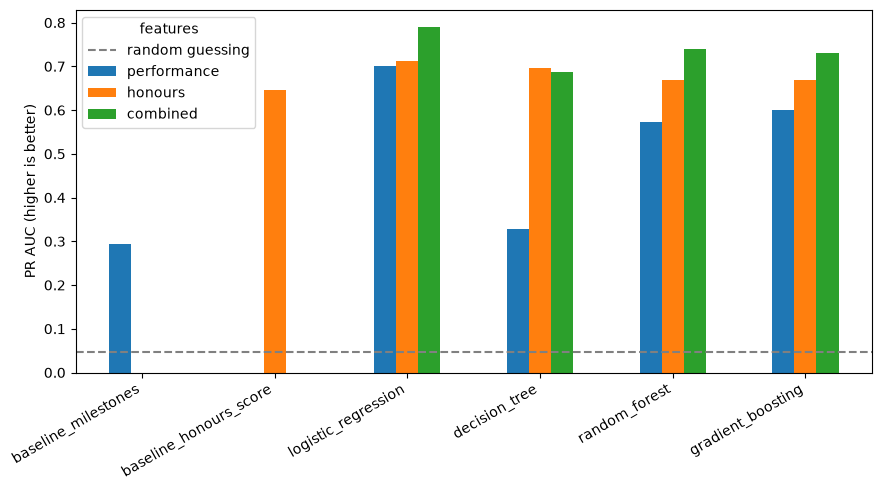

In [9]:
order = ['baseline_milestones', 'baseline_honours_score', 'logistic_regression', 'decision_tree', 'random_forest', 'gradient_boosting']
ax = table.reindex(order).plot.bar(figsize=(9, 5))
ax.axhline(y_test.mean(), color='grey', linestyle='--', label='random guessing')
ax.set_ylabel('PR AUC (higher is better)')
ax.set_xlabel('')
ax.legend(title='features')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../reports/figures/model_pr_auc.png', dpi=150)
plt.show()

## 9. What matters most?
The logistic regression gives each stat a weight. Big positive = pushes toward the Hall of Fame. Big negative = pushes away.

In [10]:
columns = feature_sets['combined']
weights_lr = trained[('logistic_regression', 'combined')][-1].coef_[0]
importance = pd.Series(weights_lr, index=columns).sort_values()
print(importance.tail(8).round(2))
print('...')
print(importance.head(5).round(2))

pos_2b      0.35
H           0.38
p_SV        0.38
AVG         0.41
p_IPouts    0.52
OBP         0.60
p_W         0.84
AllStar     1.59
dtype: float64
...
p_ERA    -0.31
p_WHIP   -0.29
pos_3b   -0.23
pos_1b   -0.21
pos_of   -0.17
dtype: float64


## 10. Save for the next step
Each model's test probabilities for the error analysis.

In [11]:
out = test[['playerID', 'name', 'final_year', 'pos', 'HOF', 'hof_route']].copy()
for (name, features), scores in test_scores.items():
    out[name + '__' + features] = scores

out.to_csv(ROOT / 'data' / 'processed' / 'test_predictions.csv', index=False)
results.to_csv(ROOT / 'data' / 'processed' / 'model_results.csv', index=False)
print('Saved', out.shape)

Saved (695, 20)
